# Import Ntuple

In [65]:
%load_ext autoreload
%autoreload 2
import matplotlib as mpl_
mpl_.rcParams['savefig.dpi'] = 300           # default dpi for every savefig
mpl_.rcParams['savefig.bbox'] = 'tight'      # never clip outside legends
mpl_.rcParams['pdf.fonttype'] = 42           # embed TrueType fonts (editable text, no journal complaints)
%config InlineBackend.figure_format = 'retina'   # sharper inline display in Jupyter

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import uproot
from tqdm.auto import tqdm
import sys
sys.path.append('/home/belle/zhangboy/inclusive_R_D/scripts/tools/')
import utilities as util
import fitting
import plotting

training_variables = util.training_variables
columns = util.all_relevant_variables
offline_cut = util.offline_cut
lgb_tight = util.lgb_tight
lgb_loose = util.lgb_loose
lgb_comb = util.lgb_comb
lgb_all = 'ell_p>0'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# Run1 e mode

# Load data files e
MC_run1_e = uproot.concatenate(['/home/belle/zhangboy/inclusive_R_D/Samples/MC16rd/offres_run1_luna_1/*.root:B0_e'],
                          library="pd",
                          cut = offline_cut,
                          filter_branch=lambda branch: branch.name in columns)

data_run1_e = uproot.concatenate(['/home/belle/zhangboy/inclusive_R_D/Samples/Data/offres_run1_luna_1.root:B0_e'],
                          library="pd",
                          cut = offline_cut,
                          filter_branch=lambda branch: branch.name in columns)

util.add_derived_variables([MC_run1_e, data_run1_e,])
    

samples_run1_e = util.classify_mc_dict(MC_run1_e, 'e', template=False)
mpl_run1_e=plotting.mpl(samples_run1_e, data_run1_e)

Classification check passed: all 462747 candidates uniquely classified into 16 categories.


cut= (5<B0_roeMbc_my_mask) & (-4<B0_roeDeltae_my_mask) & (B0_roeDeltae_my_mask<1) & (B0_dr<0.1) & (ell_p<4)


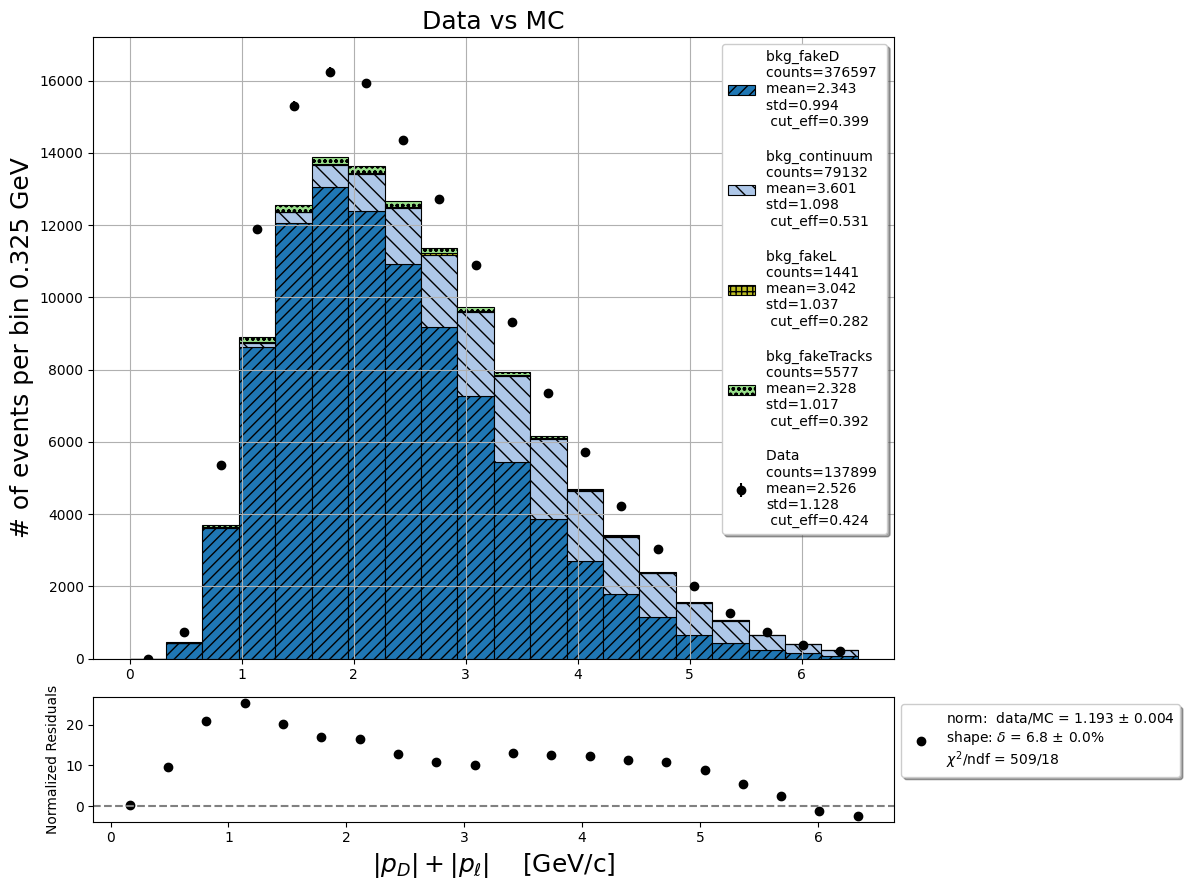

In [10]:
# showing the fake D and sidebands in D_M
b1 = np.linspace(0,6.5,21)
weights={'all_mc':0.25,}
data_hist_all, mc_hist_all = mpl_run1_e.plot_data_mc_stacked(
    variable='p_D_l',bins=b1,cut=offline_cut,mask=[],figsize=(12,9),legend_nc=1,legend_fs=10,text_fs=18,
    weights=weights,apply_eventByEvent_correction=False, eventByEvent_weight_col='total_PIDweight')

In [3]:
for df in [MC_run1_e,data_run1_e,]:
    # df.eval(f'cos_D_l = (D_px*ell_px + D_py*ell_py + D_pz*ell_pz)/(D_p*ell_p)', inplace=True)
    df.eval('B_D_ReChi2 = B0_vtxReChi2 + D_vtxReChi2', inplace=True)
    df.eval('p_D_l = D_CMS_p + ell_CMS_p', inplace=True)
    df.eval('B0_roeMbc_cor = ( (10.58/2)**2 - (B0_CMS_roeP_my_mask*10.58/Ecms)**2 )**0.5', inplace=True)
    df.eval('B0_roeDeltae_cor = B0_CMS_roeE_my_mask*10.58/Ecms - 10.58/2', inplace=True)
    df['B0_roeMbc_ori'] = df['B0_roeMbc_my_mask']
    df['B0_roeMbc_my_mask'] = df['B0_roeMbc_cor']
    df['B0_roeDeltae_ori'] = df['B0_roeDeltae_my_mask']
    df['B0_roeDeltae_my_mask'] = df['B0_roeDeltae_cor']

In [55]:
bdt_final = 'sig_prob>0.52 and fakeD_prob<0.13 and continuum_prob<0.11'

mc_run1e_final = util.apply_mva_bcs(MC_run1_e, training_variables, bdt_final, model='multiclass',library='lgbm')
data_run1e_final = util.apply_mva_bcs(data_run1_e, training_variables, bdt_final, model='multiclass',library='lgbm')

mc_run1e_final = util.apply_pid_corrections(df=mc_run1e_final, run='run1', channel='e', corr_col_name='total_PIDweight')

mc_run1e_samples=util.classify_mc_dict(mc_run1e_final, 'e', template=False)
mpl=plotting.mpl(mc_run1e_samples,data_run1e_final)
mpl_mc = plotting.mpl(mc_run1e_samples)

Event multiplicity distribution:
1    3956
2      56
3       4
Name: count, dtype: int64
Average candidates/event before BCS: 1.016
Fraction of events with >1 candidate: 1.494%
Is best selected True
Event multiplicity distribution:
1    1202
2      25
3       1
Name: count, dtype: int64
Average candidates/event before BCS: 1.022
Fraction of events with >1 candidate: 2.117%
Is best selected True
Required variables: ['ell_BFbrems_charge', 'ell_BFbrems_p', 'ell_BFbrems_cosTheta', 'ell_BFbrems_PDG', 'ell_BFbrems_mcPDG']
Required variables: ['K_charge', 'K_p', 'K_cosTheta', 'K_PDG', 'K_mcPDG']
Required variables: ['pi1_charge', 'pi1_p', 'pi1_cosTheta', 'pi1_PDG', 'pi1_mcPDG']
Required variables: ['pi2_charge', 'pi2_p', 'pi2_cosTheta', 'pi2_PDG', 'pi2_mcPDG']
Classification check passed: all 4016 candidates uniquely classified into 16 categories.


cut= sig_prob>0.52 and fakeD_prob<0.13 and continuum_prob<0.11


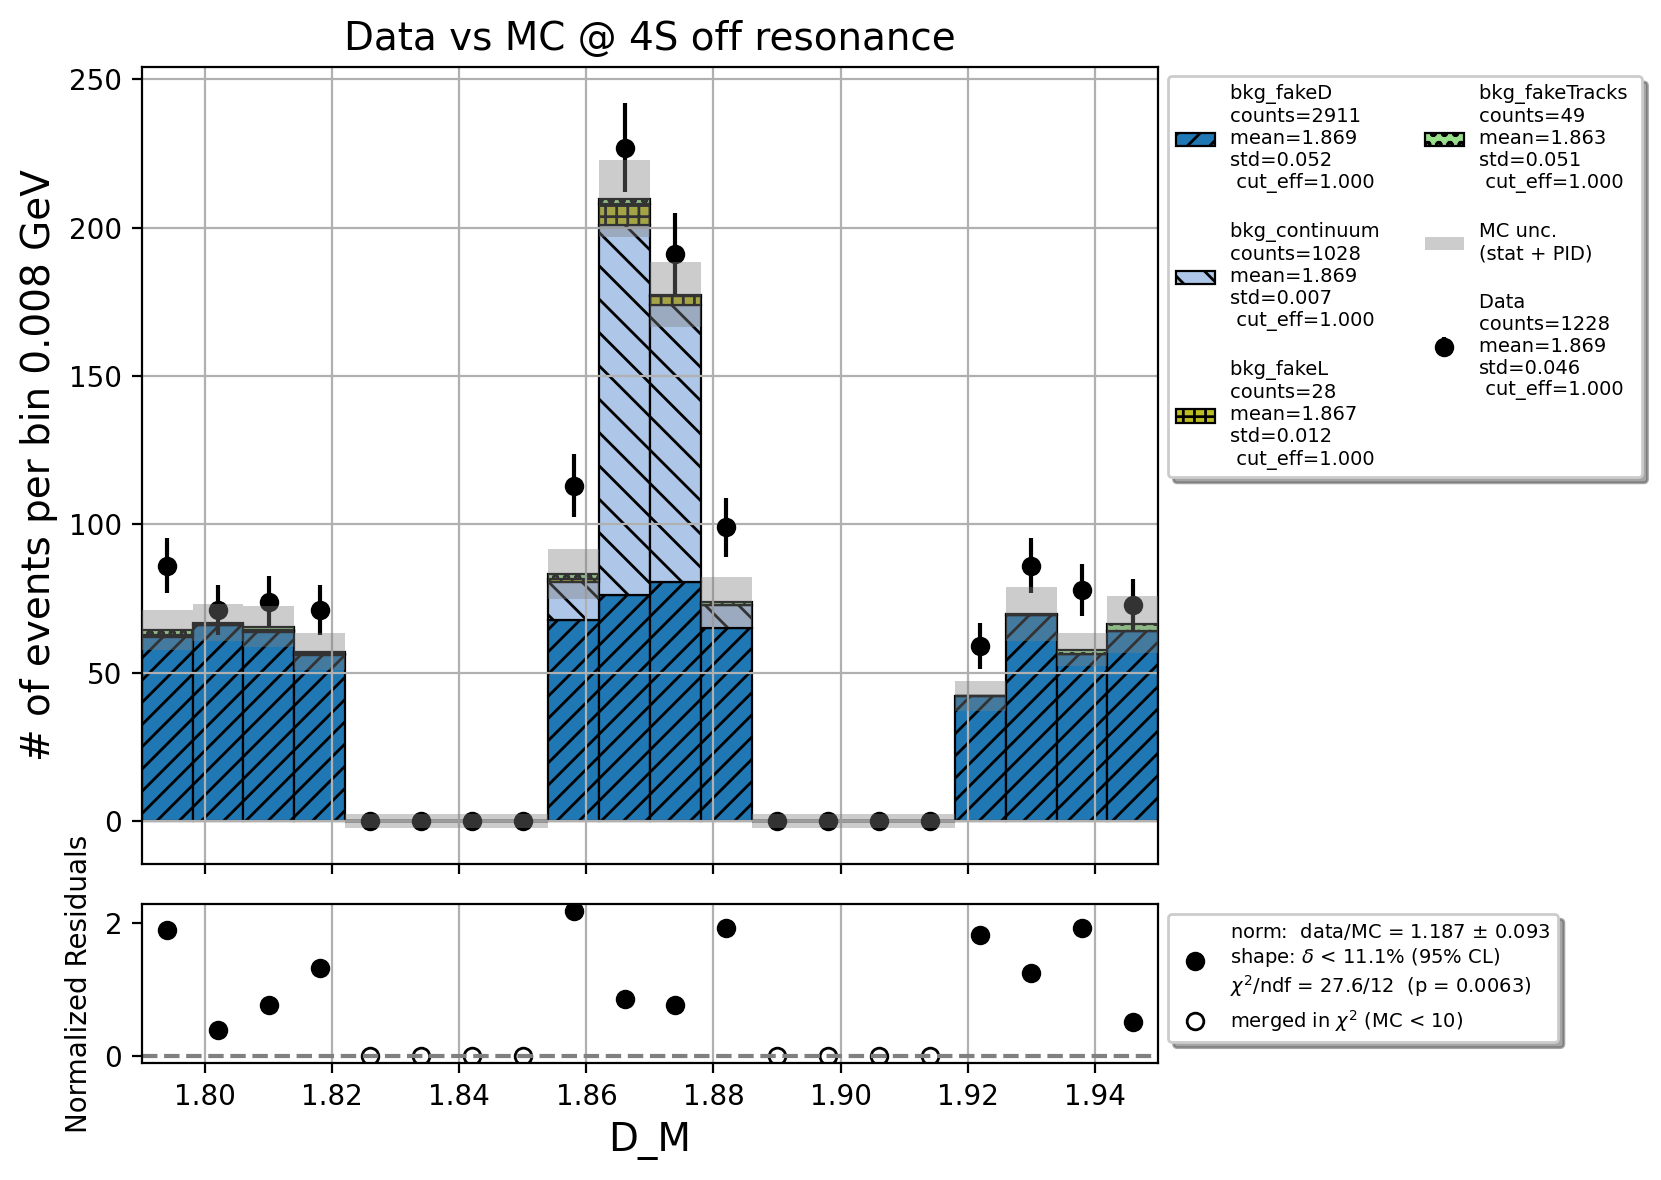

In [76]:
# BDT signal region
b1 = np.linspace(1.79,1.95,21)
weights={'all_mc':0.25}
data_hist_all, mc_hist_all = mpl.plot_data_mc_stacked(
    variable='D_M',bins=b1,cut=bdt_final,mask=[],title='Data vs MC @ 4S off resonance',
    figsize=(8,6),legend_nc=2,legend_fs=7,weights=weights,mc_uncertainty=True,
    apply_eventByEvent_correction=True, eventByEvent_weight_col='total_PIDweight')

cut= (D_M<1.855 or 1.885<D_M) and sig_prob>0.52 and fakeD_prob<0.13 and continuum_prob<0.11


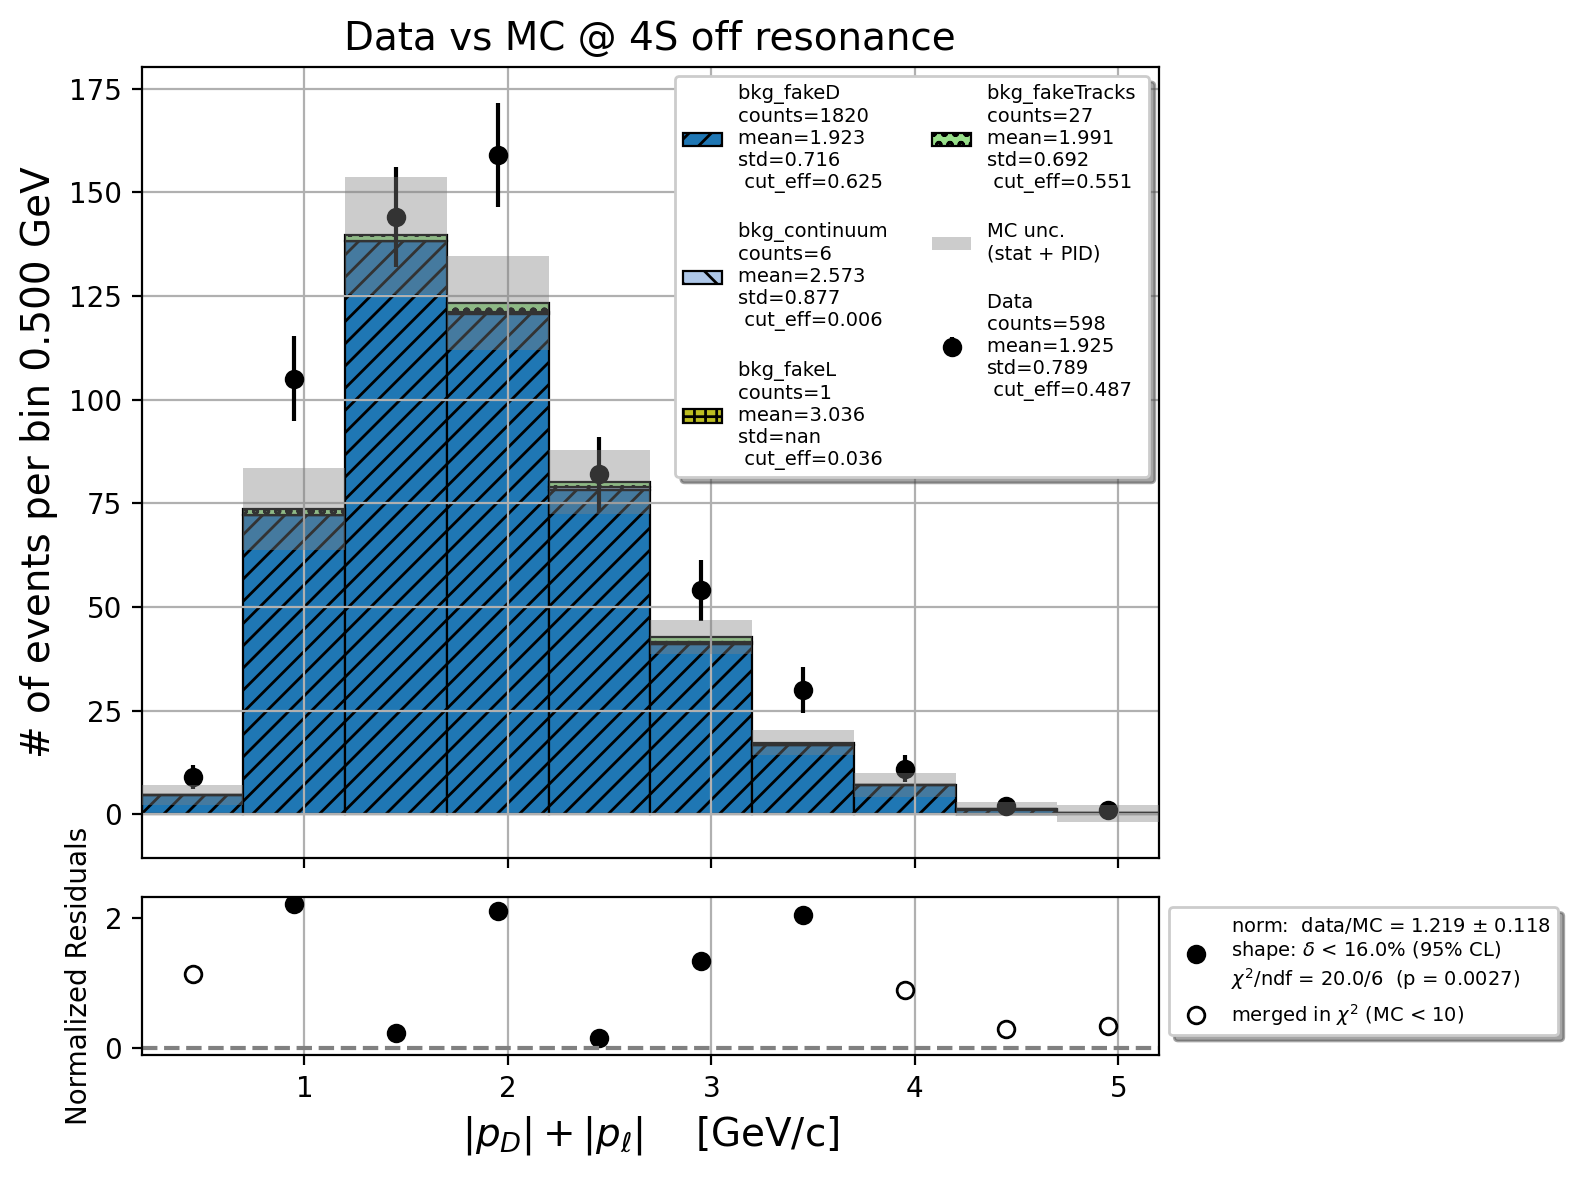

In [77]:
b1 = np.linspace(0.2,5.2,11)
weights={'all_mc':0.25}
data_hist_all, mc_hist_all = mpl.plot_data_mc_stacked(
    variable='p_D_l',bins=b1,cut=f'(D_M<1.855 or 1.885<D_M) and {bdt_final}',mask=[],
    figsize=(8,6),legend_nc=2,legend_fs=7,weights=weights,mc_uncertainty=True,title='Data vs MC @ 4S off resonance',
    apply_eventByEvent_correction=True, eventByEvent_weight_col='total_PIDweight')

cut= (D_M<1.855 or 1.885<D_M) and sig_prob>0.52 and fakeD_prob<0.13 and continuum_prob<0.11


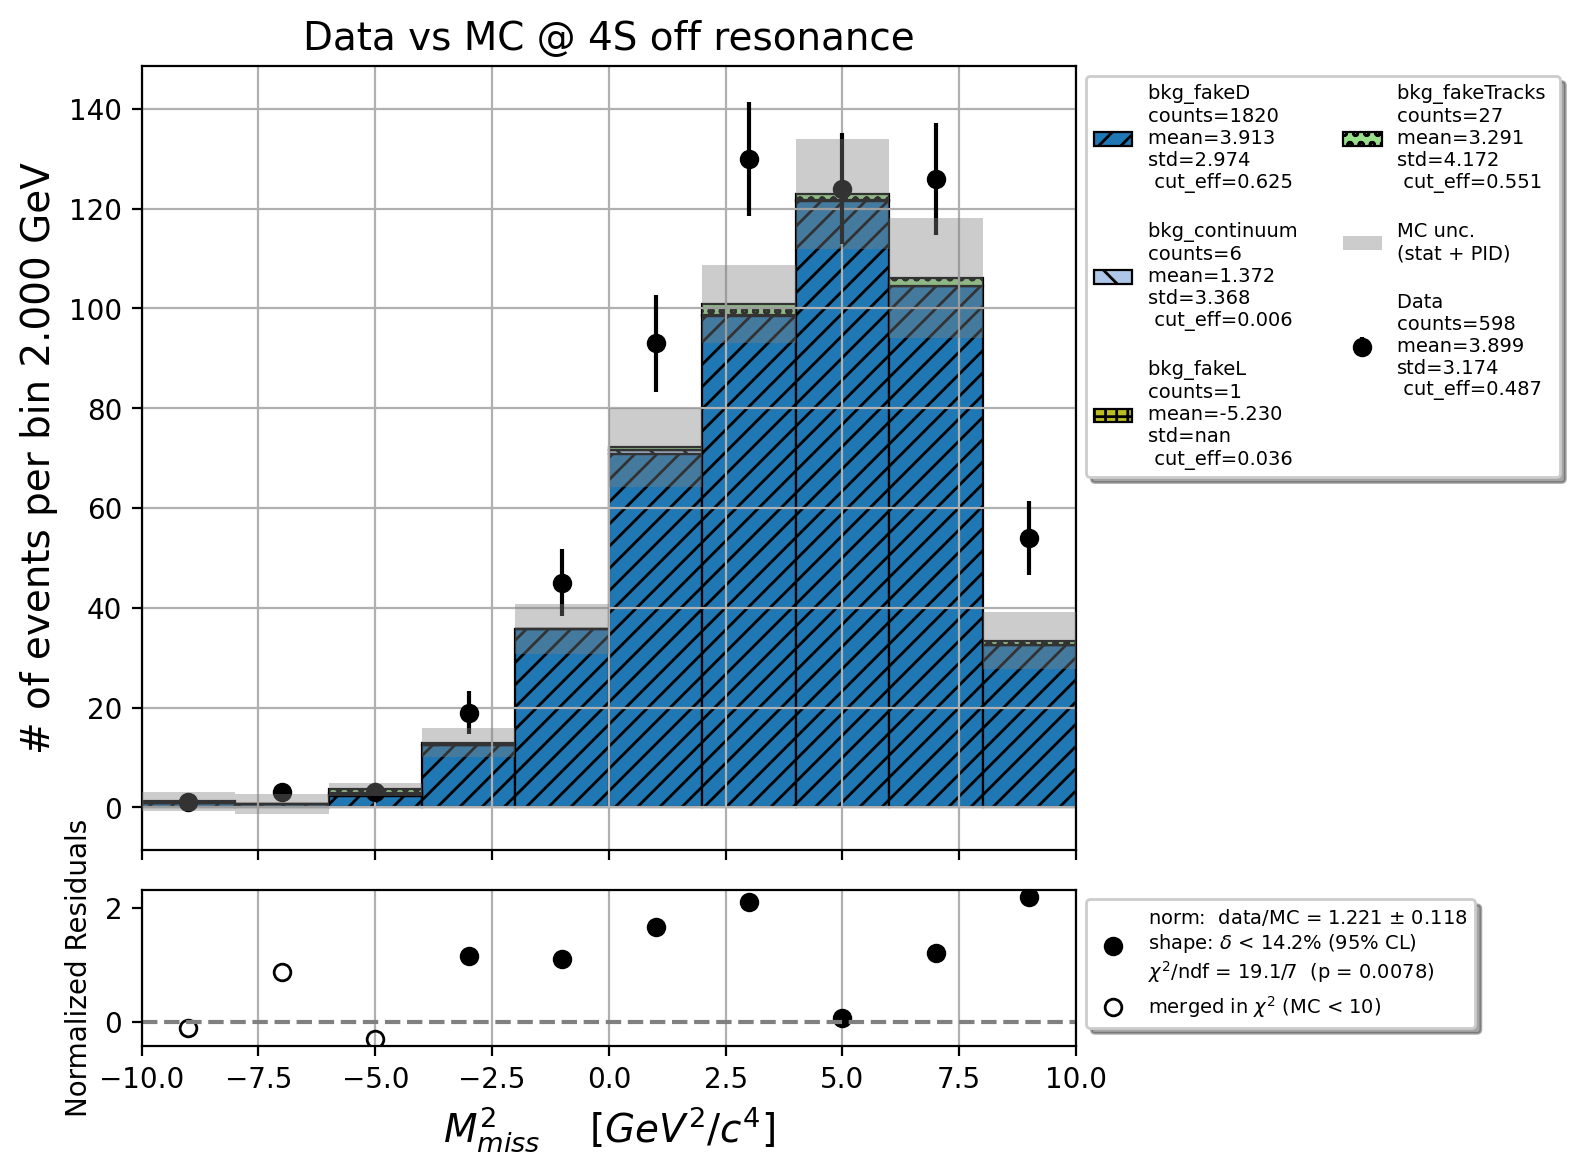

In [78]:
# showing the fake D and sidebands in D_M
b1 = np.linspace(-10,10,11)
weights={'all_mc':0.25}
data_hist_all, mc_hist_all = mpl.plot_data_mc_stacked(
    variable='B0_recMissM2',bins=b1,cut=f'(D_M<1.855 or 1.885<D_M) and {bdt_final}',mask=[],
    figsize=(8,6),legend_nc=2,legend_fs=7,weights=weights,mc_uncertainty=True,title='Data vs MC @ 4S off resonance',
    apply_eventByEvent_correction=True, eventByEvent_weight_col='total_PIDweight')

cut= 1.855<D_M<1.885 and sig_prob>0.52 and fakeD_prob<0.13 and continuum_prob<0.11


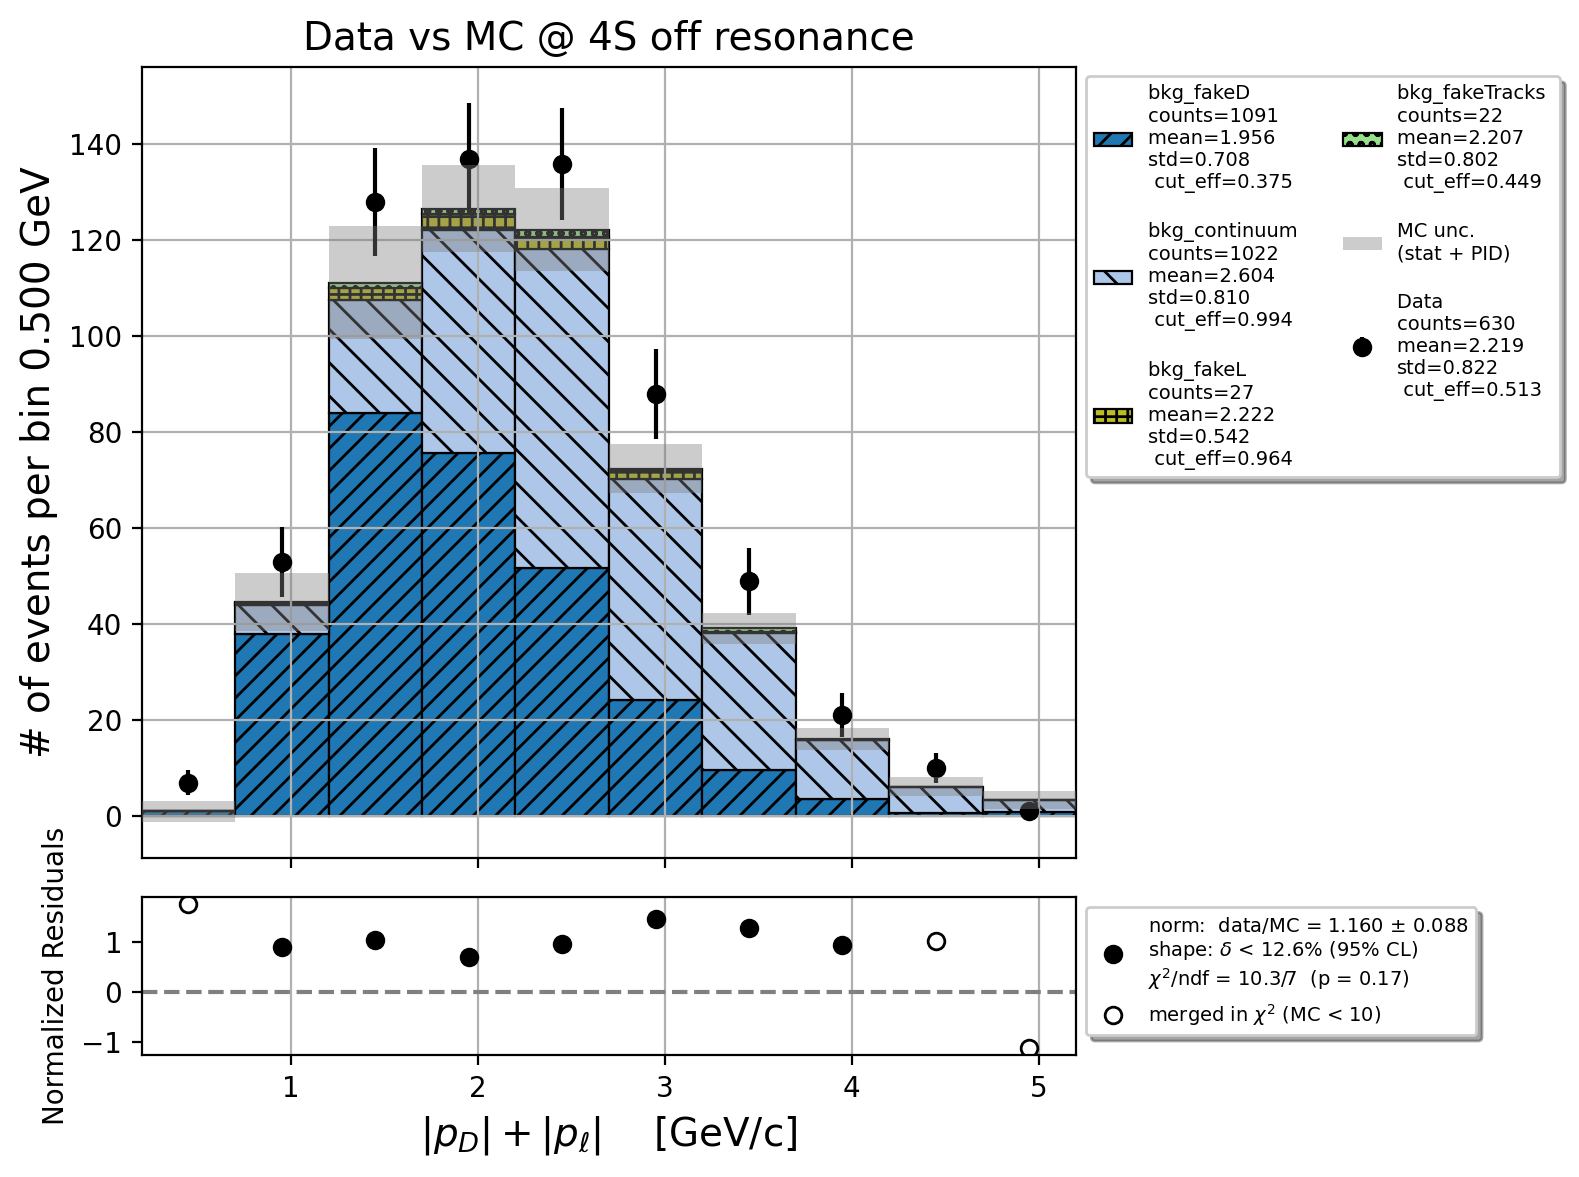

In [79]:
# showing the fake D and sidebands in D_M
b1 = np.linspace(0.2,5.2,11)
weights={'all_mc':0.25}
data_hist_all, mc_hist_all = mpl.plot_data_mc_stacked(
    variable='p_D_l',bins=b1,cut=f'1.855<D_M<1.885 and {bdt_final}',mask=[],title='Data vs MC @ 4S off resonance',
    figsize=(8,6),legend_nc=2,legend_fs=7,weights=weights,mc_uncertainty=True,
    apply_eventByEvent_correction=True, eventByEvent_weight_col='total_PIDweight')

cut= 1.855<D_M<1.885 and sig_prob>0.52 and fakeD_prob<0.13 and continuum_prob<0.11


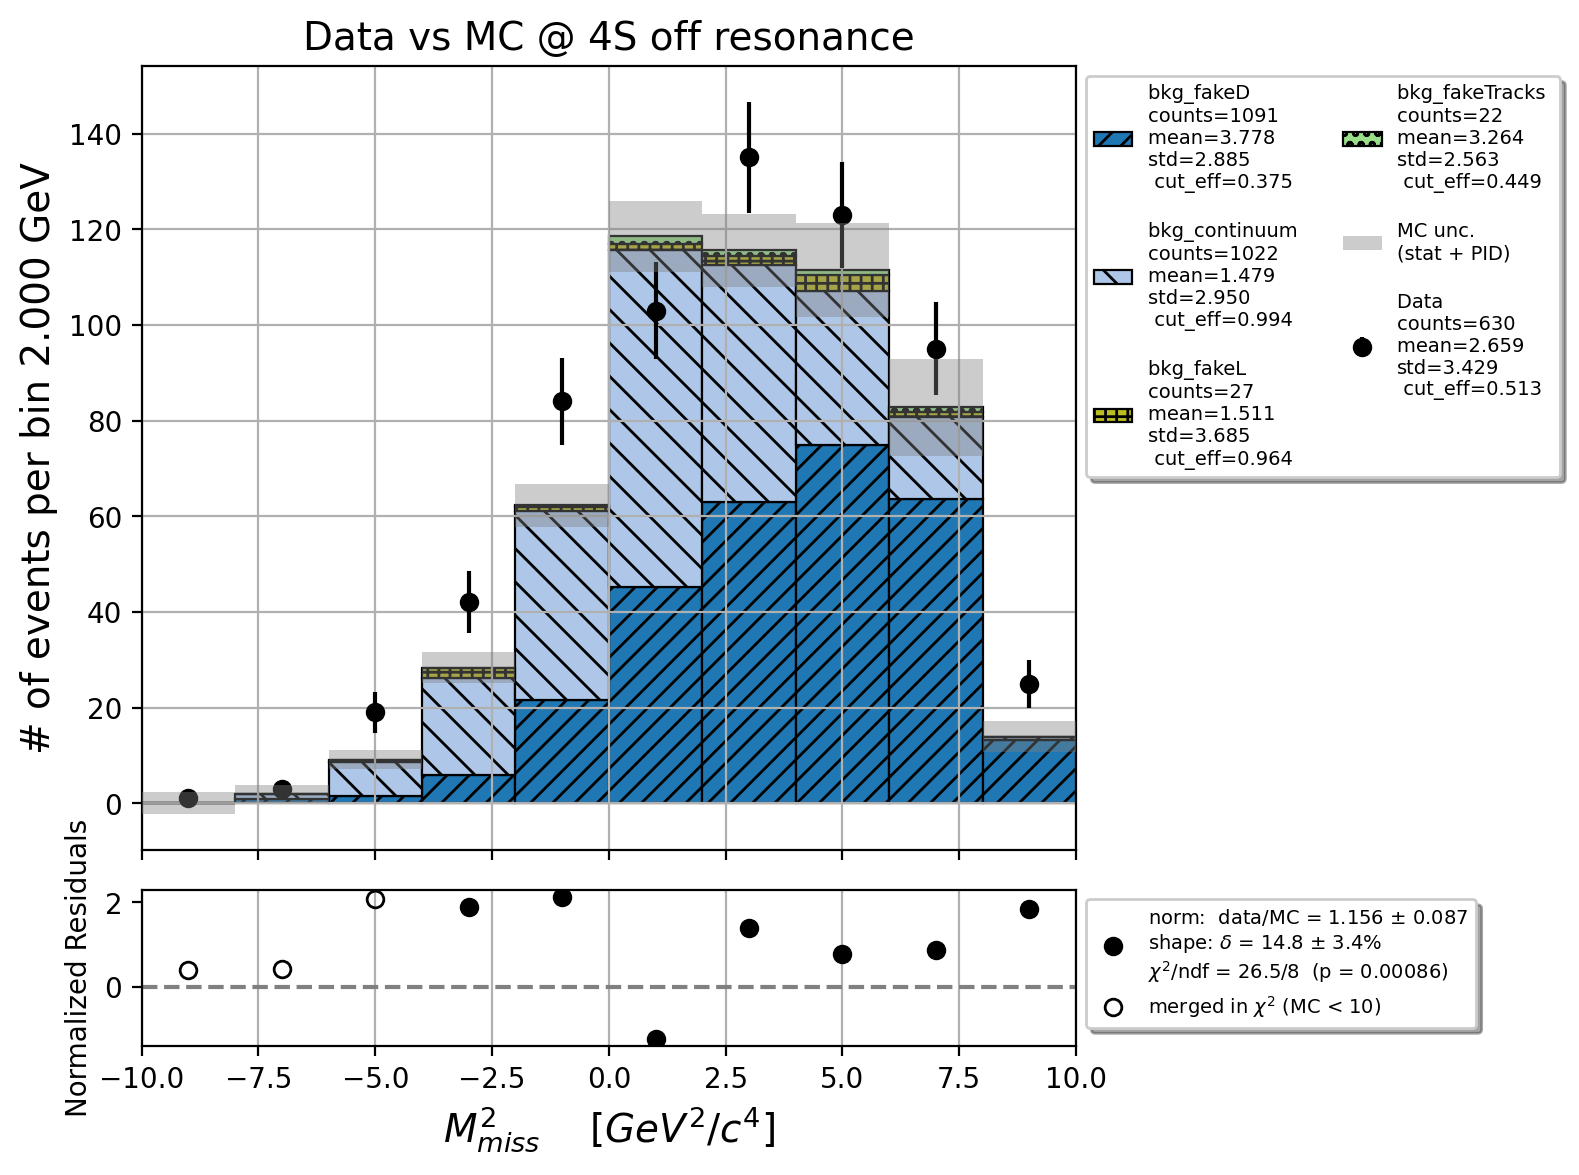

In [80]:
# showing the fake D and sidebands in D_M
b1 = np.linspace(-10,10,11)
weights={'all_mc':0.25}
data_hist_all, mc_hist_all = mpl.plot_data_mc_stacked(
    variable='B0_recMissM2',bins=b1,cut=f'1.855<D_M<1.885 and {bdt_final}',mask=[],
    figsize=(8,6),legend_nc=2,legend_fs=7,weights=weights,mc_uncertainty=True,title='Data vs MC @ 4S off resonance',
    apply_eventByEvent_correction=True, eventByEvent_weight_col='total_PIDweight')

# Check 4S vs. 4S_offres

In [ ]:
# compare control vs signal regions MC
b1 = np.linspace(-5,10,50)
scale = {'control region': 1,
         'signal region': 50/200}
mpl.plot_mc_sig_control(variable='B0_CMS3_weMissM2',bins=b1,
                        bkg_name='bkg_continuum',cut=None,
                        samples_sig=samples_sig,
                        scale=scale,correction=False,mask=[])

In [ ]:
# compare control vs signal regions MC
b1 = np.linspace(4.8,5.3,50)
scale = {'control region': 1,
         'signal region': 50/200}
mpl.plot_mc_sig_control(variable='B0_roeMbc_my_mask',bins=b1,
                        bkg_name='bkg_continuum',cut=None,
                        samples_sig=samples_sig,
                        scale=scale,correction=False,mask=[])

In [ ]:
# compare control vs signal regions MC
b1 = np.linspace(4.8,5.3,50)
scale = {'control region': 1,
         'signal region': 50/200}
mpl.plot_mc_sig_control(variable='roeMbc_cor',bins=b1,
                        bkg_name='bkg_continuum',cut=None,
                        samples_sig=samples_sig,
                        scale=scale,correction=False,mask=[])

In [ ]:
# compare control vs signal regions MC
b1 = np.linspace(-10,10,20)
scale = {'control region': 1,
         'signal region': 50/200}
mpl.plot_mc_sig_control(variable='B0_CMS3_weMissM2',bins=b1,
                        bkg_name='bkg_continuum',cut=None,
                        samples_sig=samples_sig,
                        scale=scale,correction=False,mask=[])

In [ ]:
b2 = np.linspace(0.5,5,20)
scale = {'control region': 1,
         'signal region': 50/200}
mpl.plot_mc_sig_control(variable='p_D_l',bins=b2,
                        bkg_name='bkg_continuum',cut=None,
                        samples_sig=samples_sig,
                        scale=scale,correction=False,mask=[])

In [ ]:
b2 = np.linspace(0.2,3.5,20)
scale = {'control region': 1,
         'signal region': 50/200}
mpl.plot_mc_sig_control(variable='D_CMS_p',bins=b2,
                        bkg_name='bkg_continuum',cut=None,
                        samples_sig=samples_sig,
                        scale=scale,correction=False,mask=[])

In [ ]:
b2 = np.linspace(0.2,2.5,20)
scale = {'control region': 1,
         'signal region': 50/200}
mpl.plot_mc_sig_control(variable='ell_CMS_p',bins=b2,
                        bkg_name='bkg_continuum',cut=None,
                        samples_sig=samples_sig,
                        scale=scale,correction=False,mask=[])

# Check Data vs. MC

# Create data driven template for continuum
## 1. Calculate the sidebands to sig region scaling factors
### a. Histogram the D_M distribution

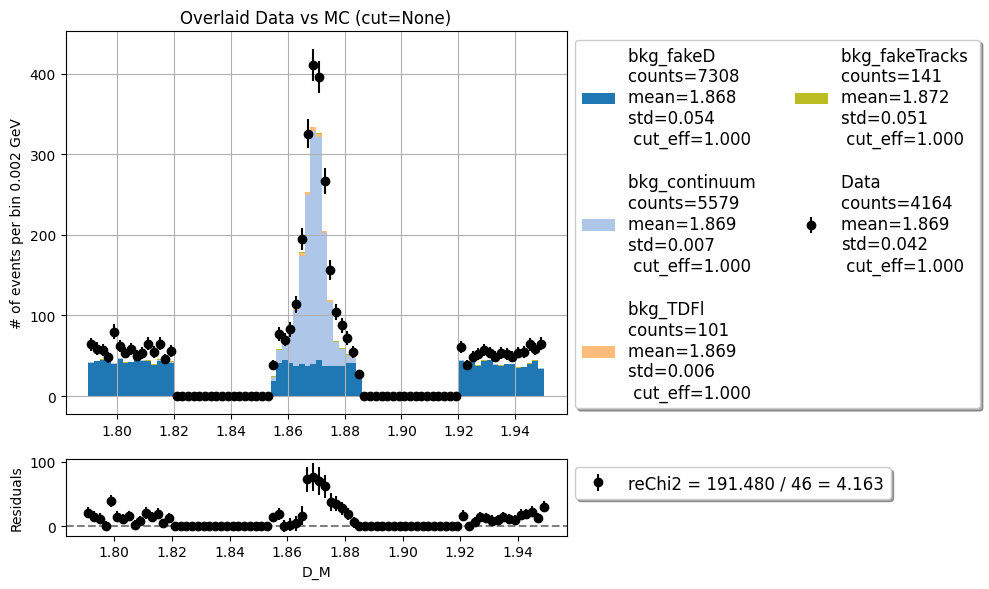

In [15]:
# BDT signal region
b1 = np.linspace(1.79,1.95,81)
weights={'all_mc':0.25}
data_hist_all, mc_hist_all = mpl.plot_data_mc_stacked(variable='D_M',bins=b1,cut=None,
                                                      weights=weights,correction=False,
                                                      mask=[],figsize=(10,6),ratio=False)

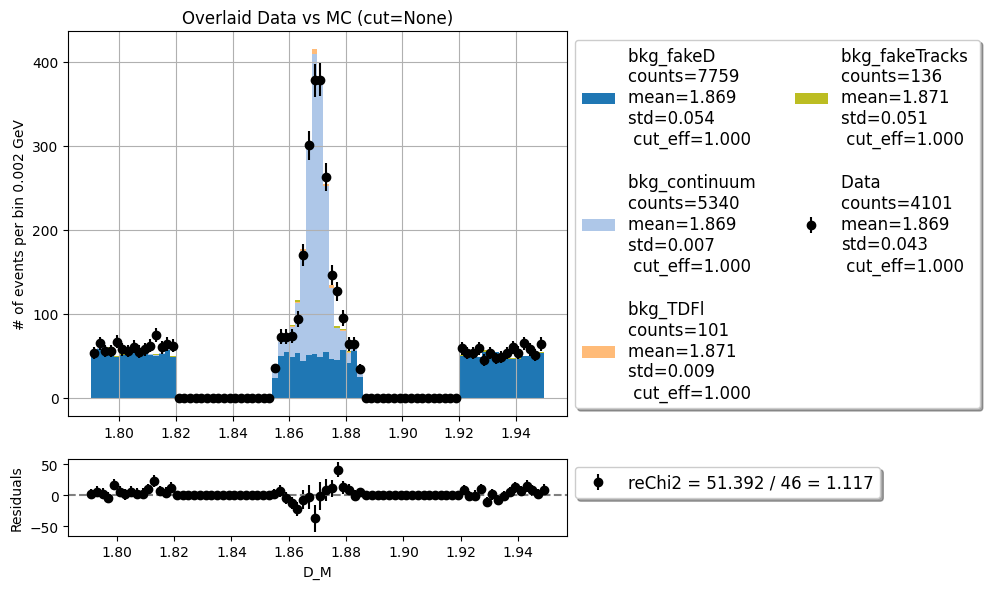

In [12]:
# BDT signal region
b1 = np.linspace(1.79,1.95,81)
weights={'all_mc':0.25*1.184}
data_hist_all, mc_hist_all = mpl.plot_data_mc_stacked(variable='D_M',bins=b1,cut=None,
                                                      weights=weights,correction=False,
                                                      mask=[],figsize=(10,6),ratio=False)

In [16]:
fitter = fitting.fit_Dmass(x_edges=b1, hist=data_hist_all, poly_only=True)

In [46]:
m_ls, c_ls, result_ls = fitter.fit_gauss_poly_LS(deg=1, loss='linear') #'soft_l1'
m_ls
# fitter.plot_poly(x=bin_edges_sb, y=data_hist_sb, yerr=data_err_sb,result=result)

initial parameters= [ 6.50e+00  1.87e+00  4.00e-02 -2.71e+01  9.29e+01]


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 14.89 (χ²/ndof = 0.6)      │              Nfcn = 40               │
│ EDM = 1.1e-13 (Goal: 0.0002)     │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬──────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼──────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ x0   │   0.00    │   0.07    │            │            │    0    │         │  yes  │
│ 1 │ x1   │   1.870   │   0.019   │            │            │    0    │         │  yes  │
│ 2 │ x2   │  40.0e-3  │  0.4e-3   │            │            │    0    │         │  yes  │
│ 3 │ x3   │    -29    │    10     │            │            │         │         │       │
│ 4 │ x4   │    96     │    19     │            │            │         │         │       │
└───┴──────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────┬──────────────────────────┐
│    │   x0   x1   x2   x3   x4 │
├────┼──────────────────────────┤
│ x0 │    0    0    0    0    0 │
│ x1 │    0    0    0    0    0 │
│ x2 │    0    0    0    0    0 │
│ x3 │    0    0    0 98.1 -180 │
│ x4 │    0    0    0 -180  345 │
└────┴──────────────────────────┘

In [17]:
m_ml, c_ml, result_ml = fitter.fit_gauss_poly_ML(deg=1)
m_ml
# fitter.plot_poly(x=bin_edges_sb, y=data_hist_sb, yerr=data_err_sb,result=result)

initial parameters= [ 8.300e+00  1.870e+00  4.000e-02  4.164e+03 -2.950e+01  1.113e+02]


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 28.2 (χ²/ndof = 1.1)       │              Nfcn = 67               │
│ EDM = 1.18e-06 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬──────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼──────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ x0   │   0.00    │   0.08    │            │            │    0    │         │  yes  │
│ 1 │ x1   │   1.870   │   0.019   │            │            │    0    │         │  yes  │
│ 2 │ x2   │  40.0e-3  │  0.4e-3   │            │            │    0    │         │  yes  │
│ 3 │ x3   │  4.49e3   │  0.11e3   │            │            │         │         │       │
│ 4 │ x4   │    -30    │    70     │            │            │         │         │       │
│ 5 │ x5   │  0.10e3   │  0.28e3   │            │            │         │         │       │
└───┴──────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────┬───────────────────────────────────────────────────────┐
│    │       x0       x1       x2       x3       x4       x5 │
├────┼───────────────────────────────────────────────────────┤
│ x0 │        0        0        0        0      0e3        0 │
│ x1 │        0        0        0        0      0e3        0 │
│ x2 │        0        0        0        0      0e3        0 │
│ x3 │        0        0        0 1.24e+04     -0e3       -0 │
│ x4 │      0e3      0e3      0e3     -0e3 5.57e+03    -21e3 │
│ x5 │        0        0        0       -0    -21e3 7.87e+04 │
└────┴───────────────────────────────────────────────────────┘

In [ ]:
area_left,error_left = fitter.poly_integral(xrange=[1.79,1.82],result=result_ls)
area_sig, error_sig = fitter.poly_integral(xrange=[1.855,1.885],result=result_ls)
area_right,error_right = fitter.poly_integral(xrange=[1.92,1.95],result=result_ls)

In [18]:
yields_left = fitter.poly_integral(xrange=[1.79,1.82],result=result_ml)
yields_sig = fitter.poly_integral(xrange=[1.855,1.885],result=result_ml)
yields_right = fitter.poly_integral(xrange=[1.92,1.95],result=result_ml)

Yields from 1.79 to 1.82 = 871.376 ± 30.151
Yields from 1.855 to 1.885 = 842.350 ± 20.891
Yields from 1.92 to 1.95 = 813.325 ± 28.349


In [50]:
print('left sideband',len(samples_4Soff['bkg_fakeD'].query('1.79<D_M<1.82'))*0.25)
print('sig region',len(samples_4Soff['bkg_fakeD'].query('1.855<D_M<1.885'))*0.25)
print('right sideband',len(samples_4Soff['bkg_fakeD'].query('1.92<D_M<1.95'))*0.25)

left sideband 641.25
sig region 588.75
right sideband 595.0


In [19]:
print('left sideband',(len(samples_4Soff['bkg_fakeD'].query('1.79<D_M<1.82'))+len(samples_4Soff['bkg_fakeTracks'].query('1.79<D_M<1.82')))*0.25)
print('sig region',(len(samples_4Soff['bkg_fakeD'].query('1.855<D_M<1.885'))+len(samples_4Soff['bkg_fakeTracks'].query('1.855<D_M<1.885')))*0.25)
print('right sideband',(len(samples_4Soff['bkg_fakeD'].query('1.92<D_M<1.95'))+len(samples_4Soff['bkg_fakeTracks'].query('1.92<D_M<1.95')))*0.25)

left sideband 650.75
sig region 609.0
right sideband 602.5


In [31]:
print(636/664, 588/641, 611/653)
print(636/608, 588/595, 610/605)

0.9578313253012049 0.9173166926677067 0.9356814701378254
1.0460526315789473 0.9882352941176471 1.0082644628099173


In [28]:
a = len(df_data_4Soffres_lgb.query('1.79<D_M<1.82'))
b = len(df_data_4Soffres_lgb.query('1.92<D_M<1.95'))
print('data',a,b, a/b)

truth 922 865 1.0658959537572255


### d. Plot and compare MC of the weighted sideband and signal region

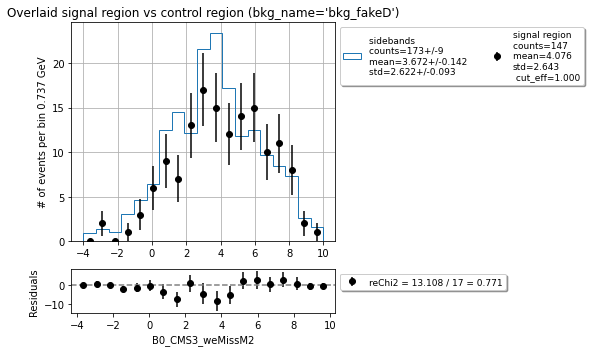

In [25]:
# showing the scaled sidebands vs. sig region from mc
b1 = np.linspace(-4,10,20)
scale = {'left sideband': yields_sig/yields_left/2,
         'signal region': 1,
         'right sideband': yields_sig/yields_right/2}
mpl.plot_mc_sig_control(variable='B0_CMS3_weMissM2',bins=b1,
                        bkg_name='bkg_fakeD',cut=None,merge_sidebands=True,
                        scale=scale,correction=False,mask=[],legend_fs=9)

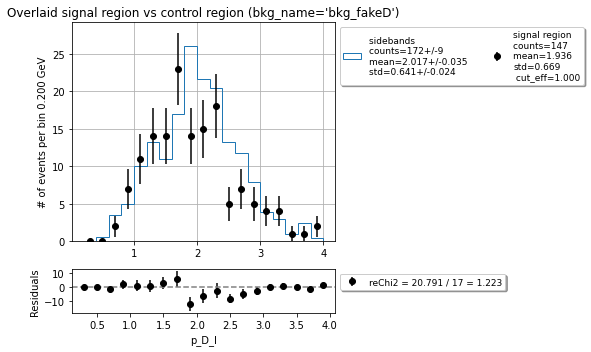

In [26]:
b2 = np.linspace(0.2,4,20)
scale = {'left sideband': yields_sig/yields_left/2,
         'signal region': 1,
         'right sideband': yields_sig/yields_right/2}
mpl.plot_mc_sig_control(variable='p_D_l',bins=b2,merge_sidebands=True,
                        bkg_name='bkg_fakeD',cut=None,
                        scale=scale,correction=False,mask=[],legend_fs=9)

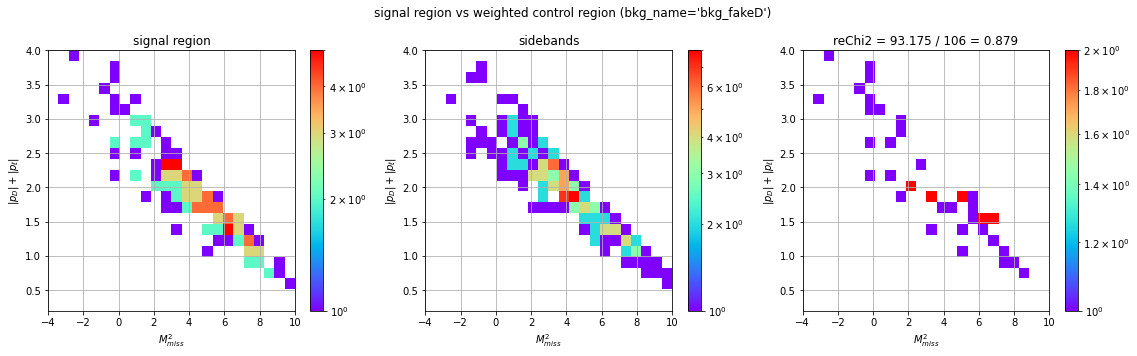

In [50]:
b1 = np.linspace(-4,10,25)
b2 = np.linspace(0.2,4,25)
scale = {'left sideband': yields_sig/yields_left/2,
         'signal region': 1,
         'right sideband': yields_sig/yields_right/2}
mpl.plot_mc_sig_control(variable=['B0_CMS3_weMissM2','p_D_l'],
                        bins=[b1,b2],
                        bkg_name='bkg_fakeD',cut=None,merge_sidebands=True,
                        scale=scale,correction=True,mask=[],figsize=(16,5))